# 02 - Exploratory Data Analysis

## Project: Urban Mobility Demand Intelligence

### Objective
Explore the Bike Sharing dataset to identify patterns, trends, and factors influencing hourly bike rental demand.

### Key areas of investigation
1. Hourly rental demand patterns
2. Daily and monthly demand trends
3. Weekday vs weekend demand
4. Seasonal demand patterns
5. Weather and temperature relationships
6. Peak demand periods

### Dataset
UCI Bike Sharing Dataset — 2011 to 2012.

**Target variable:** `cnt` (total bike rentals).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

In [2]:
df = pd.read_csv("../data/raw/hour.csv")

df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (17379, 17)

Column names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Data types:
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


In [4]:
df["cnt"].describe()

count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

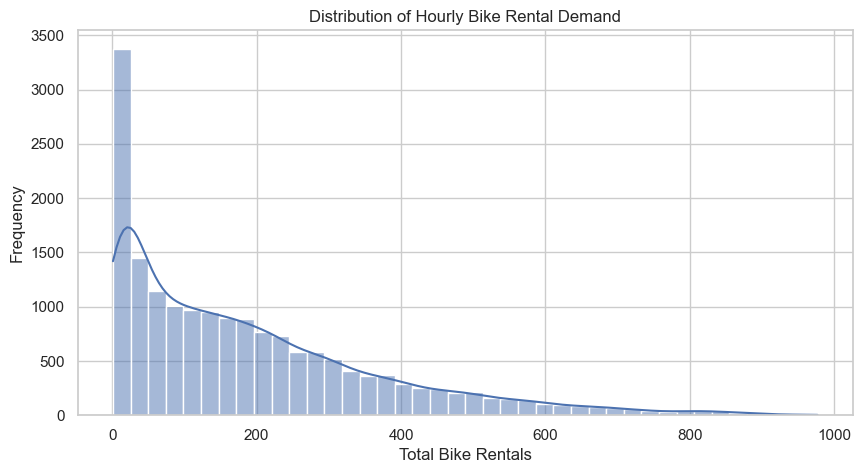

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(df["cnt"], bins=40, kde=True)

plt.title("Distribution of Hourly Bike Rental Demand")
plt.xlabel("Total Bike Rentals")
plt.ylabel("Frequency")

plt.show()

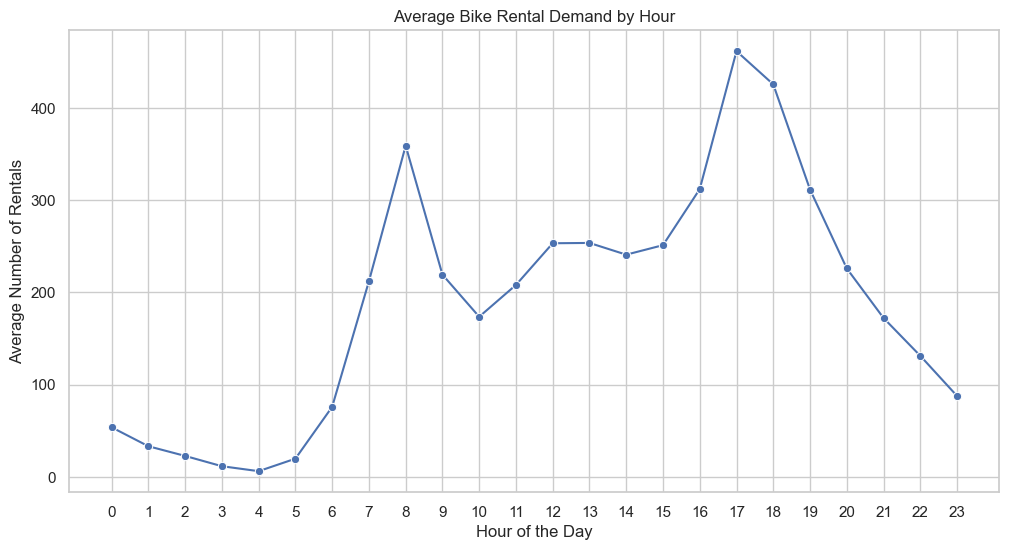

In [6]:
hourly_demand = df.groupby("hr")["cnt"].mean()

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=hourly_demand.index,
    y=hourly_demand.values,
    marker="o"
)

plt.title("Average Bike Rental Demand by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.grid(True)

plt.show()

In [7]:
df["day_type"] = df["workingday"].map({
    0: "Weekend / Holiday",
    1: "Working Day"
})

day_demand = df.groupby("day_type")["cnt"].mean()

print(day_demand)

day_type
Weekend / Holiday    181.405332
Working Day          193.207754
Name: cnt, dtype: float64


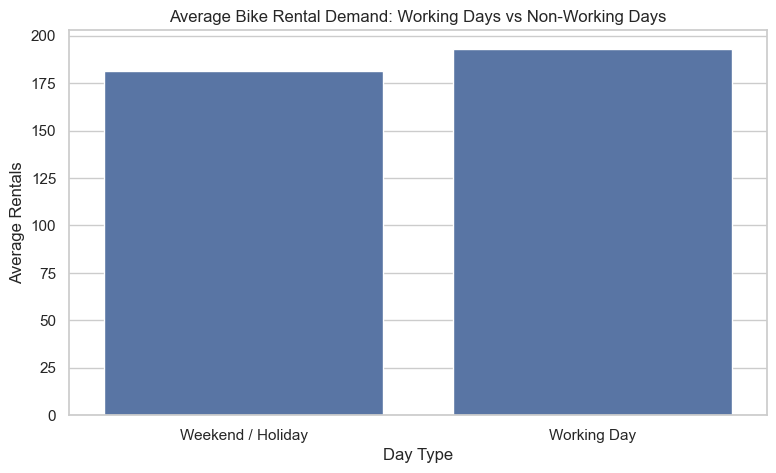

In [9]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="day_type",
    y="cnt",
    estimator="mean",
    errorbar=None
)

plt.title("Average Bike Rental Demand: Working Days vs Non-Working Days")
plt.xlabel("Day Type")
plt.ylabel("Average Rentals")

plt.show()

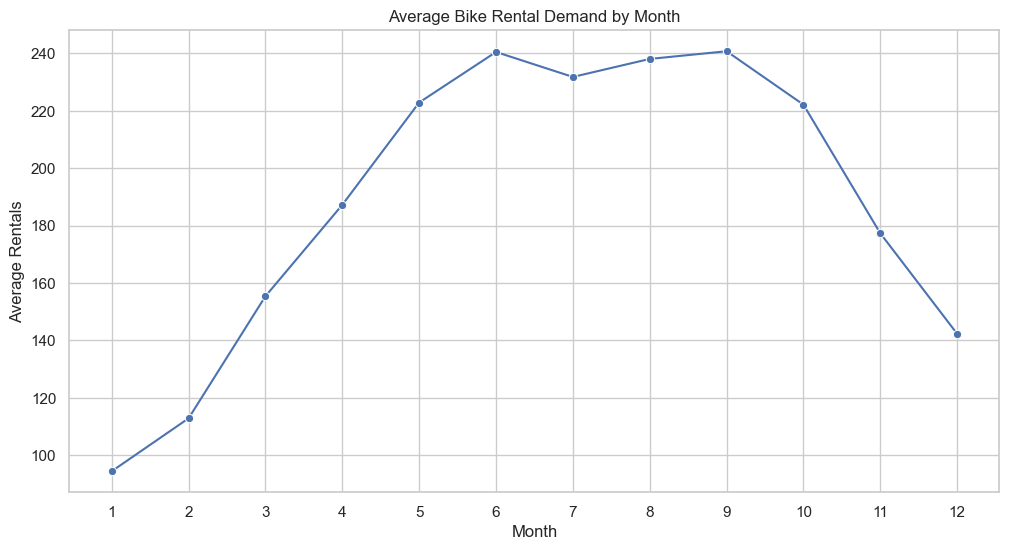

In [10]:
monthly_demand = df.groupby("mnth")["cnt"].mean()

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=monthly_demand.index,
    y=monthly_demand.values,
    marker="o"
)

plt.title("Average Bike Rental Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Rentals")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

In [11]:
print("Highest demand month:", monthly_demand.idxmax())
print("Highest average rentals:", round(monthly_demand.max(), 2))

print("\nLowest demand month:", monthly_demand.idxmin())
print("Lowest average rentals:", round(monthly_demand.min(), 2))

Highest demand month: 9
Highest average rentals: 240.77

Lowest demand month: 1
Lowest average rentals: 94.42


In [12]:
weather_demand = df.groupby("weathersit")["cnt"].mean()

print(weather_demand)

weathersit
1    204.869272
2    175.165493
3    111.579281
4     74.333333
Name: cnt, dtype: float64


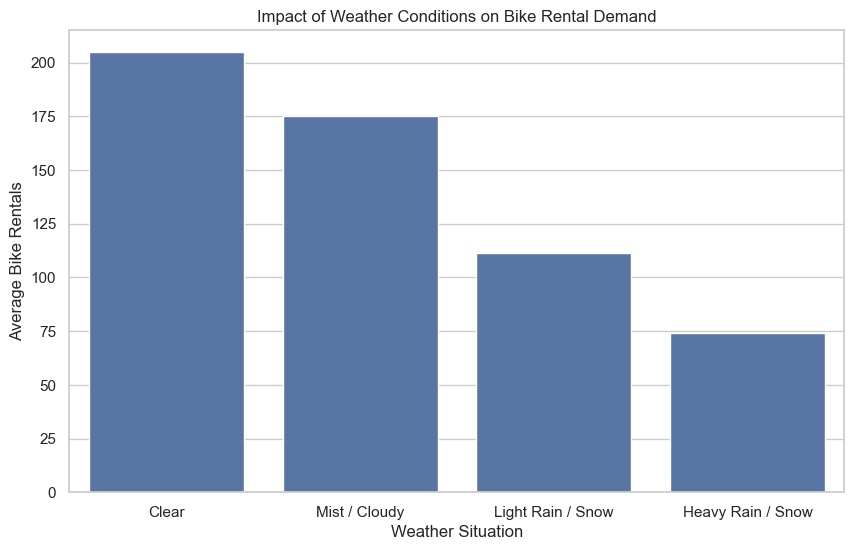

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="weathersit",
    y="cnt",
    estimator="mean",
    errorbar=None
)

plt.title("Impact of Weather Conditions on Bike Rental Demand")
plt.xlabel("Weather Situation")
plt.ylabel("Average Bike Rentals")

plt.xticks(
    [0, 1, 2, 3],
    ["Clear", "Mist / Cloudy", "Light Rain / Snow", "Heavy Rain / Snow"]
)

plt.show()

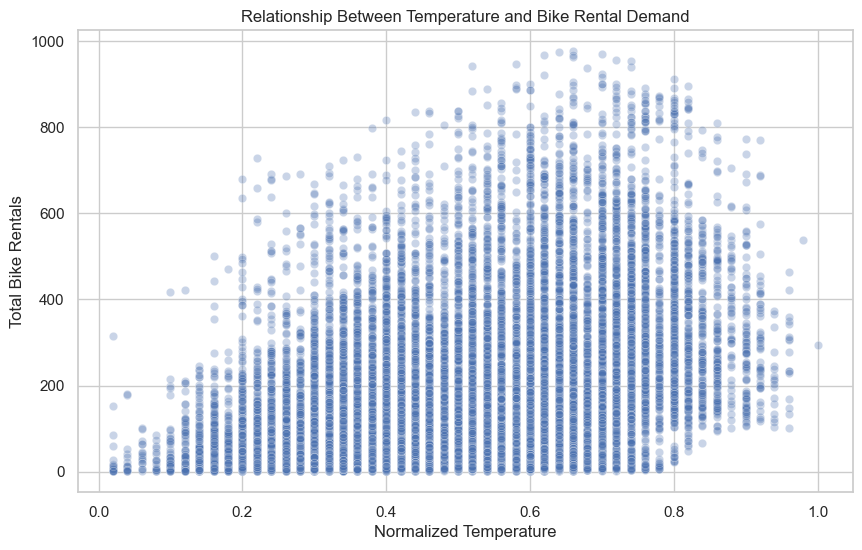

In [14]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="temp",
    y="cnt",
    alpha=0.3
)

plt.title("Relationship Between Temperature and Bike Rental Demand")
plt.xlabel("Normalized Temperature")
plt.ylabel("Total Bike Rentals")

plt.show()

In [15]:
correlation = df["temp"].corr(df["cnt"])

print("Temperature-Demand Correlation:", round(correlation, 3))

Temperature-Demand Correlation: 0.405


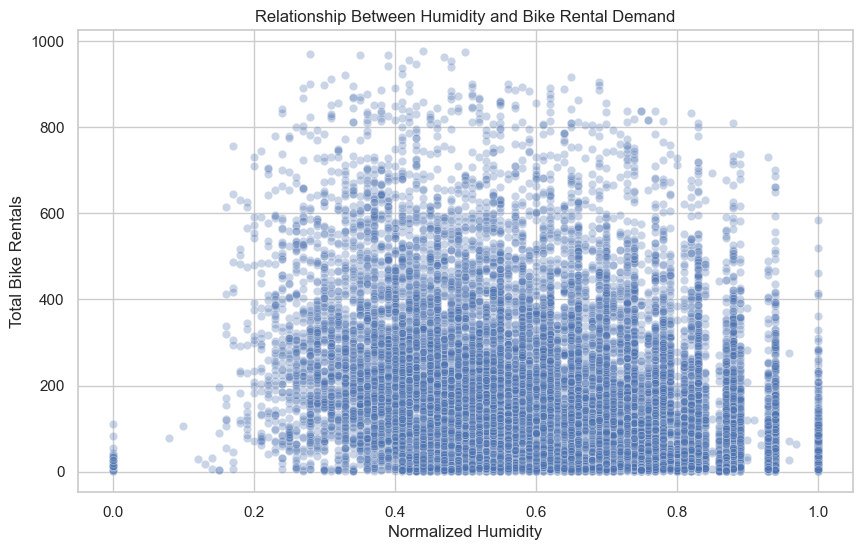

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="hum",
    y="cnt",
    alpha=0.3
)

plt.title("Relationship Between Humidity and Bike Rental Demand")
plt.xlabel("Normalized Humidity")
plt.ylabel("Total Bike Rentals")

plt.show()

In [18]:
humidity_corr = df["hum"].corr(df["cnt"])

print("Humidity-Demand Correlation:", round(humidity_corr, 3))

Humidity-Demand Correlation: -0.323


In [19]:
print("Humidity correlation:", round(df["hum"].corr(df["cnt"]), 3))
print("Windspeed correlation:", round(df["windspeed"].corr(df["cnt"]), 3))

Humidity correlation: -0.323
Windspeed correlation: 0.093


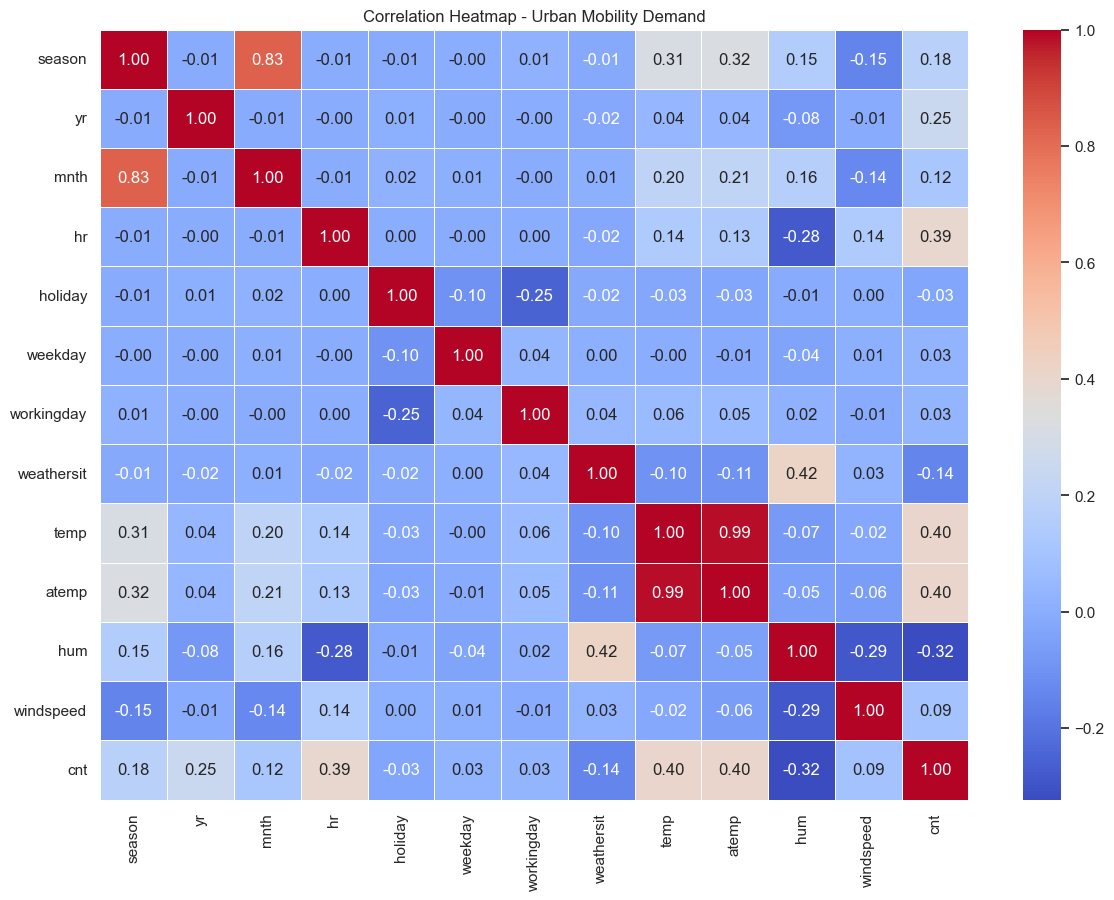

In [20]:
numeric_df = df.select_dtypes(include=["number"])

# Remove identifier and component columns
numeric_df = numeric_df.drop(
    columns=["instant", "casual", "registered"],
    errors="ignore"
)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Urban Mobility Demand")
plt.show()

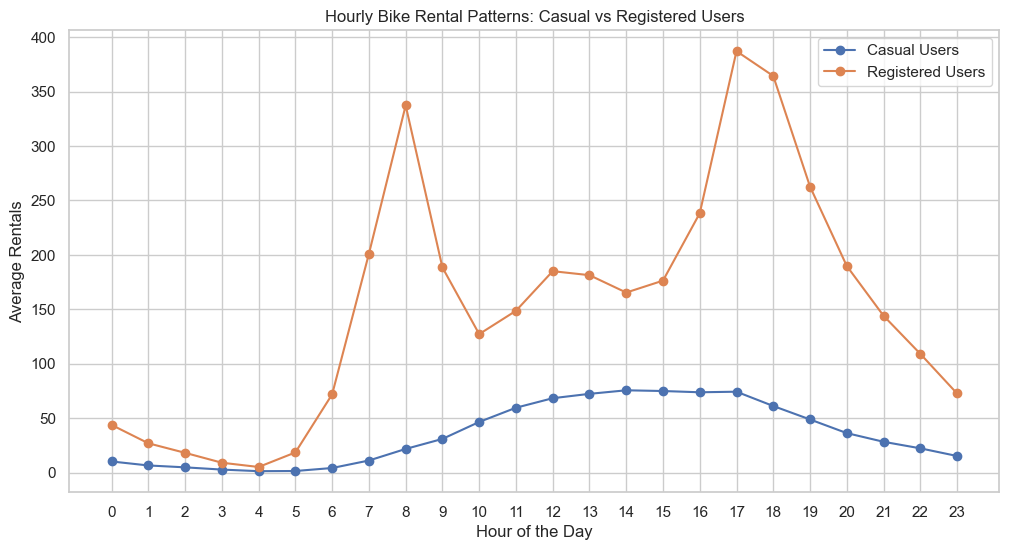

In [21]:
user_demand = df.groupby("hr")[["casual", "registered"]].mean()

plt.figure(figsize=(12, 6))

plt.plot(
    user_demand.index,
    user_demand["casual"],
    marker="o",
    label="Casual Users"
)

plt.plot(
    user_demand.index,
    user_demand["registered"],
    marker="o",
    label="Registered Users"
)

plt.title("Hourly Bike Rental Patterns: Casual vs Registered Users")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rentals")
plt.xticks(range(24))
plt.legend()
plt.grid(True)

plt.show()

In [22]:
day_segment = df.groupby("workingday")[["casual", "registered"]].mean()

day_segment.index = ["Weekend / Holiday", "Working Day"]

print(day_segment)

                      casual  registered
Weekend / Holiday  57.441422  123.963910
Working Day        25.561315  167.646439


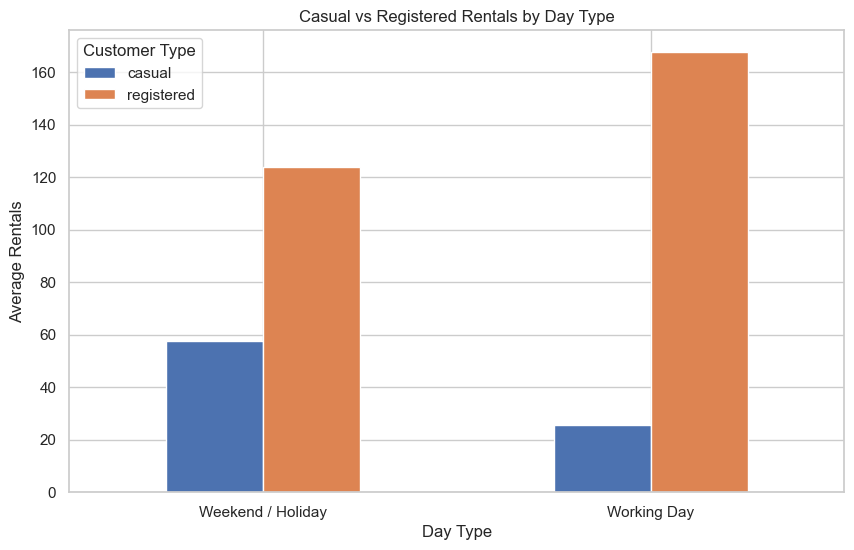

In [23]:
day_segment.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Casual vs Registered Rentals by Day Type")
plt.xlabel("Day Type")
plt.ylabel("Average Rentals")
plt.xticks(rotation=0)
plt.legend(title="Customer Type")
plt.show()


## Key EDA Findings

### 1. Hourly Demand
- Demand peaks around 08:00 and 17:00–18:00.
- Demand is lowest during early morning hours.

### 2. Working Days vs Non-Working Days
- Working days have slightly higher average overall demand.

### 3. Monthly Demand
- Demand is highest around June and September.
- January has the lowest average demand.

### 4. Weather Relationships
- Clear weather is associated with higher rental demand.
- Temperature has a moderate positive correlation with demand (r = 0.405).
- Humidity has a moderate negative correlation (r = -0.323).
- Windspeed has a very weak positive correlation (r = 0.093).

### 5. Customer Segmentation
- Registered users show strong morning and evening peaks.
- Casual users show higher demand during afternoon hours.
- Registered users contribute more demand on working days.
- Casual users contribute relatively more demand on weekends and holidays.

### 6. Feature Relationships
- Temperature and feeling temperature are highly correlated (r = 0.99).
- Season and month are strongly correlated (r = 0.83).

## Conclusion

The exploratory analysis reveals that hourly bike rental demand is influenced by temporal patterns, weather conditions and customer behaviour.

These findings will guide feature selection and model development in the next stages.
